## 1. Install

In [1]:
!pip install -q mediapipe opencv-python-headless scikit-learn joblib

## 2. Settings and Google Drive

In [3]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob, zipfile

DRIVE_ROOT = '/content/drive/MyDrive'
ZIP_PATH   = DRIVE_ROOT + '/ASL_Dataset.zip'
MODEL_PATH = DRIVE_ROOT + '/asl_rf.joblib'
WORK_DIR   = '/content/asl'
PER_CLASS  = 500
RETRAIN    = False

Mounted at /content/drive


## 3. Hand detector and helper functions

In [4]:
import cv2, numpy as np, urllib.request
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision

MODEL_URL = 'https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task'
HAND_MODEL = 'hand_landmarker.task'
if not os.path.exists(HAND_MODEL):
    urllib.request.urlretrieve(MODEL_URL, HAND_MODEL)

detector = vision.HandLandmarker.create_from_options(vision.HandLandmarkerOptions(
    base_options=mp_python.BaseOptions(model_asset_path=HAND_MODEL),
    running_mode=vision.RunningMode.IMAGE,
    num_hands=1,
    min_hand_detection_confidence=0.5))

def detect_hand(img_bgr):
    """Returns the 21 landmarks of the first detected hand, or None."""
    rgb = np.ascontiguousarray(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
    result = detector.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))
    return result.hand_landmarks[0] if result.hand_landmarks else None

def landmarks_to_features(lm):
    """21 landmarks -> 63 numbers, independent of hand position and size."""
    pts = np.array([[p.x, p.y, p.z] for p in lm], dtype=np.float32)
    pts -= pts[0]                      # wrist at the origin
    scale = np.abs(pts).max()
    if scale > 0:
        pts /= scale
    return pts.flatten()

print('Hand detector ready.')

Hand detector ready.


## 4. Load the saved model, or train it

In [5]:
import random, joblib
from tqdm.auto import tqdm
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

IMG_EXT = ('.jpg', '.jpeg', '.png', '.bmp')

def locate_zip():
    if os.path.exists(ZIP_PATH):
        return ZIP_PATH
    hits = []
    for pattern in ('/*.zip', '/*/*.zip', '/*/*/*.zip'):
        for p in glob.glob(DRIVE_ROOT + pattern):
            n = os.path.basename(p).lower()
            if 'asl' in n or 'sign' in n or 'alphabet' in n:
                hits.append(p)
    if hits:
        print('ZIP_PATH not found, using:', hits[0])
        return hits[0]
    raise FileNotFoundError('Dataset zip not found in Google Drive. Check the file name and set ZIP_PATH in step 2.')

def unpack_dataset():
    os.makedirs(WORK_DIR, exist_ok=True)
    if os.listdir(WORK_DIR):
        print('Dataset already unpacked.'); return
    with zipfile.ZipFile(locate_zip()) as z:
        z.extractall(WORK_DIR)
    for _ in range(3):                                   # Mendeley sometimes nests zips
        inner = glob.glob(WORK_DIR + '/**/*.zip', recursive=True)
        if not inner:
            break
        for zp in inner:
            with zipfile.ZipFile(zp) as z:
                z.extractall(os.path.dirname(zp))
            os.remove(zp)

def find_split(name):
    for root, dirs, _ in os.walk(WORK_DIR):
        for d in dirs:
            if d.lower() == name:
                p = os.path.join(root, d)
                subs = [s for s in os.listdir(p) if os.path.isdir(os.path.join(p, s))]
                if len(subs) >= 20:
                    return p
    return None

def extract_split(split_dir, per_class=None, seed=42):
    rng = random.Random(seed)
    X, y, missed = [], [], 0
    for cls in tqdm(sorted(os.listdir(split_dir))):
        cdir = os.path.join(split_dir, cls)
        if not os.path.isdir(cdir):
            continue
        paths = [os.path.join(cdir, f) for f in os.listdir(cdir) if f.lower().endswith(IMG_EXT)]
        rng.shuffle(paths)
        if per_class:
            paths = paths[:per_class]
        for p in paths:
            img = cv2.imread(p)
            if img is None:
                continue
            lm = detect_hand(img)
            if lm is not None:
                X.append(landmarks_to_features(lm)); y.append(cls.upper())
            else:
                missed += 1
    print(f'{os.path.basename(split_dir)}: kept {len(X)} images, no hand detected in {missed}')
    return np.array(X), np.array(y)

if os.path.exists(MODEL_PATH) and not RETRAIN:
    clf = joblib.load(MODEL_PATH)
    print('Loaded saved model from Drive. Letters:', ' '.join(clf.classes_))
else:
    unpack_dataset()
    train_dir, test_dir = find_split('train'), find_split('test')
    print('Train folder:', train_dir)
    print('Test folder :', test_dir)
    assert train_dir, 'Could not find the Train folder. Check the dataset zip contents.'

    X_tr, y_tr = extract_split(train_dir, PER_CLASS)
    if test_dir:
        X_te, y_te = extract_split(test_dir, PER_CLASS)
    else:
        from sklearn.model_selection import train_test_split
        X_tr, X_te, y_tr, y_te = train_test_split(X_tr, y_tr, test_size=0.2, stratify=y_tr, random_state=42)

    # Mirror augmentation: add x-flipped copies of the training data so both left and right hands work.
    flip = np.where(np.arange(63) % 3 == 0, -1, 1)
    X_tr = np.vstack([X_tr, X_tr * flip]); y_tr = np.concatenate([y_tr, y_tr])

    clf = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=42)
    clf.fit(X_tr, y_tr)

    pred = clf.predict(X_te)
    print('\nTest accuracy:', round(accuracy_score(y_te, pred), 4))
    print(classification_report(y_te, pred))
    fig, ax = plt.subplots(figsize=(11, 11))
    ConfusionMatrixDisplay.from_predictions(y_te, pred, ax=ax, xticks_rotation=90, colorbar=False)
    plt.show()

    joblib.dump(clf, MODEL_PATH)
    print('Model saved to Google Drive:', MODEL_PATH)

Loaded saved model from Drive. Letters: A B C D E F G H I K L M N O P Q R S T U V W X Y


## ACCURACY METRICS

  0%|          | 0/25 [00:00<?, ?it/s]

Test: kept 678 images, no hand detected in 42
Test images    : 678
Test accuracy  : 0.8127  (81.27%)

           Precision    Recall  F1 score
Macro         0.8389    0.8126    0.8047
Weighted      0.8369    0.8127    0.8031

Per-letter results:
              precision    recall  f1-score   support

           A       0.56      0.97      0.71        30
           B       0.97      0.97      0.97        29
           C       0.93      0.89      0.91        28
           D       0.69      0.96      0.81        28
           E       0.96      0.93      0.95        29
           F       1.00      1.00      1.00        30
           G       1.00      0.83      0.91        29
           H       0.85      1.00      0.92        29
           I       1.00      0.65      0.79        20
           K       1.00      0.90      0.95        30
           L       0.92      0.83      0.87        29
           M       0.96      0.96      0.96        28
           N       0.93      0.93      0.93        

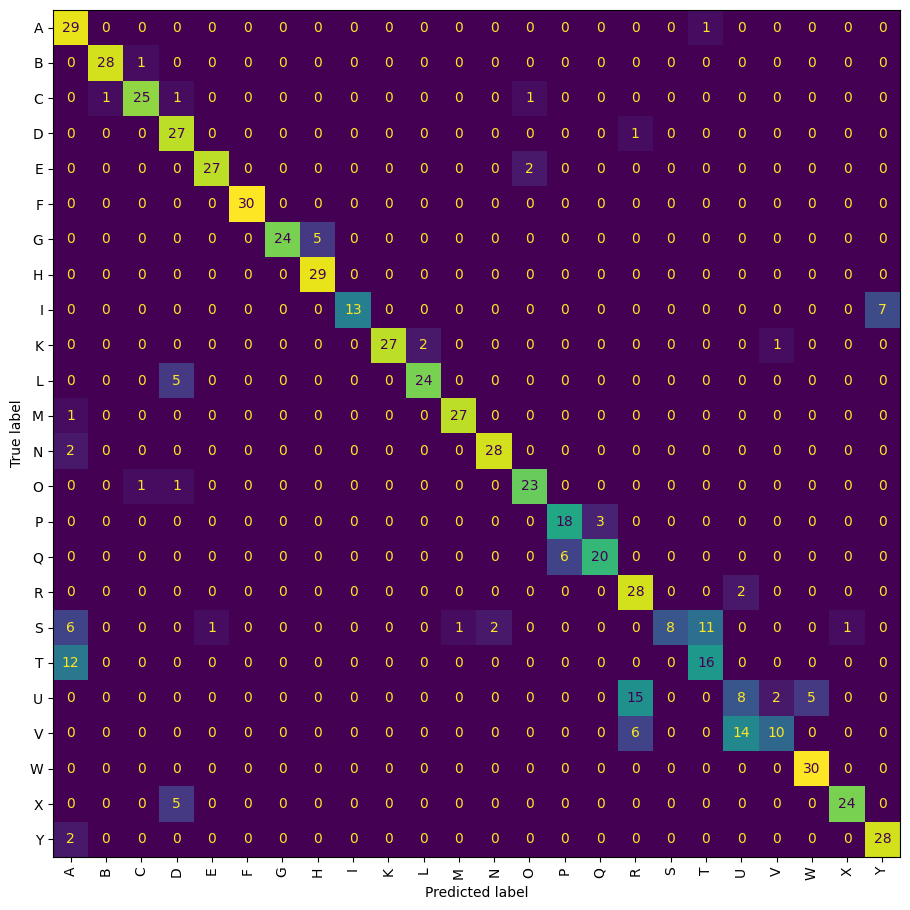

In [8]:
import collections
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

# 1) Landmarks of the Test images (about 30 seconds)
unpack_dataset()
X_test, y_test = extract_split(find_split('test'), PER_CLASS)

# 2) Predict with the current model (clf)
y_pred = clf.predict(X_test)

# 3) Metrics
acc = accuracy_score(y_test, y_pred)
mac_p, mac_r, mac_f, _ = precision_recall_fscore_support(y_test, y_pred, average='macro', zero_division=0)
wtd_p, wtd_r, wtd_f, _ = precision_recall_fscore_support(y_test, y_pred, average='weighted', zero_division=0)

print(f'Test images    : {len(y_test)}')
print(f'Test accuracy  : {acc:.4f}  ({acc*100:.2f}%)\n')
print(f'{"":10s}{"Precision":>10s}{"Recall":>10s}{"F1 score":>10s}')
print(f'{"Macro":10s}{mac_p:10.4f}{mac_r:10.4f}{mac_f:10.4f}')
print(f'{"Weighted":10s}{wtd_p:10.4f}{wtd_r:10.4f}{wtd_f:10.4f}\n')

print('Per-letter results:')
print(classification_report(y_test, y_pred, zero_division=0))

# 4) Where the remaining mistakes are
pairs = collections.Counter((t, p) for t, p in zip(y_test, y_pred) if t != p)
print('Most common mistakes (true -> predicted):')
for (t, p), n in pairs.most_common(10):
    print(f'  {t} -> {p}: {n}')

# 5) Confusion matrix
fig, ax = plt.subplots(figsize=(11, 11))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, xticks_rotation=90, colorbar=False)
plt.show()

## 5. Live word builder

In [7]:
import time, base64, collections, numpy as np, cv2
from IPython.display import display, Javascript, JSON
from google.colab import output

HOLD_SECONDS = 1.0    # hold a sign steady this long to type the letter
MIN_CONF     = 0.60   # ignore low-confidence guesses
SPACE_AFTER  = 1.8    # take your hand out of view this long to add a space

state = dict(text='', cand=None, since=0.0, armed=True,
             last_hand=time.time(), recent=collections.deque(maxlen=5))

def _process(data_url):
    now = time.time()
    s = state
    img = cv2.imdecode(np.frombuffer(base64.b64decode(data_url.split(',')[1]), np.uint8), cv2.IMREAD_COLOR)
    lm = detect_hand(img)

    if lm is None:                                   # no hand in view
        s['recent'].clear(); s['cand'] = None; s['armed'] = True
        if s['text'] and not s['text'].endswith(' ') and now - s['last_hand'] >= SPACE_AFTER:
            s['text'] += ' '
        return JSON({'found': False, 'text': s['text'], 'progress': 0.0})

    s['last_hand'] = now
    probs = clf.predict_proba(landmarks_to_features(lm).reshape(1, -1))[0]
    i = int(probs.argmax()); conf = float(probs[i])
    s['recent'].append(str(clf.classes_[i]))
    stable = collections.Counter(s['recent']).most_common(1)[0][0]

    progress = 0.0
    if conf < MIN_CONF:
        s['cand'] = None
    else:
        if stable != s['cand']:                      # new letter: start the hold timer
            s['cand'] = stable; s['since'] = now; s['armed'] = True
        if s['armed']:
            progress = min((now - s['since']) / HOLD_SECONDS, 1.0)
            if progress >= 1.0:                      # held long enough: type it
                s['text'] += stable
                s['armed'] = False                   # same letter won't repeat until hand leaves or sign changes
    return JSON({'found': True, 'label': stable, 'conf': conf, 'progress': progress,
                 'text': s['text'], 'points': [[float(p.x), float(p.y)] for p in lm]})

def process_frame(data_url):
    try:
        return _process(data_url)
    except Exception as e:      # show the problem on the video instead of failing silently
        return JSON({'found': False, 'error': type(e).__name__ + ': ' + str(e),
                     'text': state['text'], 'progress': 0.0})

def control(action):
    t = state['text']
    if action == 'space' and t and not t.endswith(' '):
        state['text'] = t + ' '
    elif action == 'backspace':
        state['text'] = t[:-1]
    elif action == 'clear':
        state['text'] = ''
    return JSON({'text': state['text']})

output.register_callback('notebook.process_frame', process_frame)
output.register_callback('notebook.control', control)

JS = """
(async () => {
  const container = document.createElement('div');
  const bar = document.createElement('div');
  const mk = (label, fn) => { const b = document.createElement('button'); b.textContent = label;
                              b.style.marginRight = '6px'; b.onclick = fn; bar.appendChild(b); return b; };
  const canvas = document.createElement('canvas');
  const textDiv = document.createElement('div');
  textDiv.style.cssText = 'font: bold 28px sans-serif; margin-top: 8px; min-height: 40px; white-space: pre-wrap;';
  container.append(bar, canvas, textDiv);
  document.body.appendChild(container);

  const video = document.createElement('video');
  video.autoplay = true; video.playsInline = true;
  const stream = await navigator.mediaDevices.getUserMedia({video: {width: 640, height: 480}});
  video.srcObject = stream;
  await video.play();
  canvas.width = video.videoWidth; canvas.height = video.videoHeight;

  let running = true, busy = false, last = null;
  const control = async (a) => {
    const r = await google.colab.kernel.invokeFunction('notebook.control', [a], {});
    textDiv.textContent = r.data['application/json'].text;
  };
  mk('Space', () => control('space'));
  mk('Backspace', () => control('backspace'));
  mk('Clear', () => control('clear'));
  mk('Speak', () => speechSynthesis.speak(new SpeechSynthesisUtterance(textDiv.textContent)));
  mk('Stop', () => { running = false; });
  google.colab.output.setIframeHeight(document.documentElement.scrollHeight + 60, true);

  const ctx = canvas.getContext('2d');
  const small = document.createElement('canvas');
  small.width = 320; small.height = 240;
  const sctx = small.getContext('2d');
  const CONN = [[0,1],[1,2],[2,3],[3,4],[0,5],[5,6],[6,7],[7,8],[5,9],[9,10],[10,11],[11,12],
                [9,13],[13,14],[14,15],[15,16],[13,17],[17,18],[18,19],[19,20],[0,17]];

  async function sendFrame() {
    busy = true;
    sctx.drawImage(video, 0, 0, 320, 240);
    try {
      const res = await google.colab.kernel.invokeFunction(
          'notebook.process_frame', [small.toDataURL('image/jpeg', 0.7)], {});
      last = res.data['application/json'];
      if (last.text !== undefined) textDiv.textContent = last.text;
    } catch (e) {
      last = {found: false, error: 'No reply from Python: ' + e, progress: 0, text: textDiv.textContent};
    }
    busy = false;
  }

  function loop() {
    if (!running) {
      stream.getTracks().forEach(t => t.stop());
      bar.remove(); canvas.remove();          // keep the typed text on screen after stopping
      return;
    }
    ctx.drawImage(video, 0, 0, canvas.width, canvas.height);
    if (!busy) sendFrame();
    if (last && last.found) {
      const P = last.points.map(p => [p[0] * canvas.width, p[1] * canvas.height]);
      ctx.strokeStyle = 'white'; ctx.lineWidth = 2;
      CONN.forEach(([a, b]) => { ctx.beginPath(); ctx.moveTo(...P[a]); ctx.lineTo(...P[b]); ctx.stroke(); });
      ctx.fillStyle = 'red';
      P.forEach(p => { ctx.beginPath(); ctx.arc(p[0], p[1], 4, 0, 6.283); ctx.fill(); });
      ctx.fillStyle = 'lime'; ctx.font = 'bold 48px sans-serif';
      ctx.fillText(last.label + ' ' + Math.round(last.conf * 100) + '%', 15, 55);
      ctx.fillStyle = 'rgba(0,0,0,0.5)'; ctx.fillRect(15, 68, 200, 14);       // hold-progress bar
      ctx.fillStyle = 'lime'; ctx.fillRect(15, 68, 200 * last.progress, 14);
    }
    ctx.font = 'bold 26px sans-serif';                                          // status line
    if (!last) {
      ctx.fillStyle = 'yellow'; ctx.fillText('Waiting for Python...', 15, 45);
    } else if (last.error) {
      ctx.fillStyle = '#ff5252'; ctx.font = 'bold 20px sans-serif';
      ctx.fillText('Error: ' + last.error.slice(0, 48), 15, 35);
      ctx.fillText(last.error.slice(48, 96), 15, 62);
    } else if (!last.found) {
      ctx.fillStyle = 'yellow'; ctx.fillText('No hand detected', 15, 45);
    }
    if (last) {                                                                 // typed text strip
      ctx.fillStyle = 'rgba(0,0,0,0.6)'; ctx.fillRect(0, canvas.height - 56, canvas.width, 56);
      ctx.fillStyle = 'white'; ctx.font = 'bold 34px monospace';
      ctx.fillText(last.text.slice(-30) + '_', 12, canvas.height - 16);
    }
    requestAnimationFrame(loop);
  }
  loop();
})().catch(e => {
  const d = document.createElement('div');
  d.style.cssText = 'color:#d93025; font:18px sans-serif; padding:8px;';
  d.textContent = 'Camera error: ' + e.name + ' - ' + e.message +
      '. Click the camera icon in the address bar and choose Allow, close other apps using the camera, then run this cell again.';
  document.body.appendChild(d);
  google.colab.output.setIframeHeight(120, true);
});
"""
display(Javascript(JS))


<IPython.core.display.Javascript object>